# 07 — Matplotlib : tracer et analyser des signaux

Un oscilloscope affiche une tension en fonction du temps ; Matplotlib fait la
même chose dans un notebook. Tracer un signal permet de repérer un pic, une
saturation, un déphasage ou une non-linéarité avant même de calculer quoi que
ce soit.

**Objectifs du notebook**

- maîtriser `fig` (la figure) et `ax` (la zone de tracé) ;
- tracer un signal avec titre, axes gradués, grille et légende ;
- comparer deux signaux et marquer un seuil ;
- utiliser des sous-graphiques, un nuage de points et un diagramme en barres ;
- enregistrer une figure dans un fichier.

**Prérequis** : notebooks 01 à 06 (NumPy en particulier).


## Utilisation en ligne (Google Colab)

Cette cellule ne fait rien sur votre ordinateur. Dans Google Colab, elle
clone le dépôt public (données comprises) et place le notebook à sa racine,
afin que les chemins `data/...` fonctionnent. Exécutez-la en premier.


In [1]:
import os  # manipulation des chemins et du dossier courant
import subprocess  # lance la commande git clone
import sys  # permet de détecter l'environnement Colab

DEPOT = "https://github.com/VladdKid/python-electronique-ia.git"  # adresse publique du cours
DOSSIER = "python-electronique-ia"  # dossier local créé par le clone

if "google.colab" in sys.modules and not os.path.isdir("data"):  # uniquement dans Colab, si les données manquent
    if not os.path.isdir(DOSSIER):  # évite de cloner deux fois le dépôt
        subprocess.run(["git", "clone", "--depth", "1", DEPOT, DOSSIER], check=True)  # télécharge le cours
    os.chdir(DOSSIER)  # se place à la racine du dépôt cloné
    print(f"Dépôt prêt : {os.getcwd()}")  # confirme le dossier de travail


## 1. Figure, axes, courbe

La méthode moderne recommandée est `fig, ax = plt.subplots(...)`. `fig` est la
feuille entière, `ax` la zone où l'on dessine. Travailler avec `ax` plutôt
qu'avec `plt` directement devient indispensable dès qu'il y a plusieurs
graphiques.


In [2]:
import numpy as np  # calculs numériques
import matplotlib.pyplot as plt  # bibliothèque de tracé


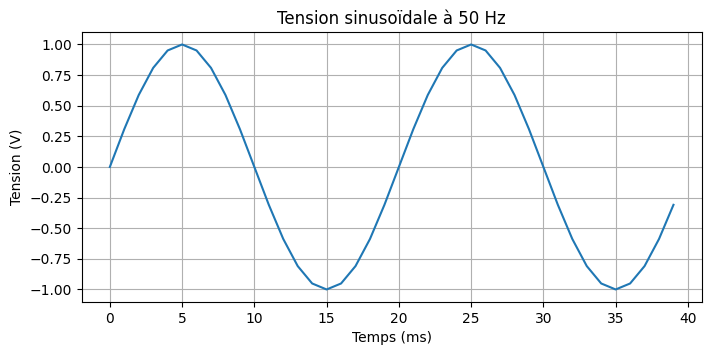

In [3]:
fs = 1000.0  # 1000 échantillons par seconde
f_signal = 50.0  # signal de 50 Hz, comme le réseau électrique
t = np.arange(0.0, 0.04, 1.0 / fs)  # 40 ms de signal, soit deux périodes
signal = 1.0 * np.sin(2.0 * np.pi * f_signal * t)  # sinusoïde d'amplitude 1 V

fig, ax = plt.subplots(figsize=(8.0, 3.5))  # crée une figure de 8 × 3,5 pouces
ax.plot(t * 1000.0, signal)  # trace le signal ; l'axe x est converti en millisecondes
ax.set_title("Tension sinusoïdale à 50 Hz")  # titre du graphique
ax.set_xlabel("Temps (ms)")  # légende de l'axe horizontal
ax.set_ylabel("Tension (V)")  # légende de l'axe vertical
ax.grid(True)  # ajoute une grille pour faciliter la lecture
plt.show()  # affiche la figure dans le notebook


`ax.plot` reçoit d'abord les abscisses puis les ordonnées. Sans `plt.show()`,
la figure reste en mémoire et s'affiche tout de même en fin de cellule ; on
garde l'appel explicite pour l'habitude.


## 2. Comparer deux signaux et marquer un seuil

On superpose le signal propre et le signal bruité, puis on matérialise le
seuil de déclenchement d'une alarme avec `axhline` (ligne horizontale).


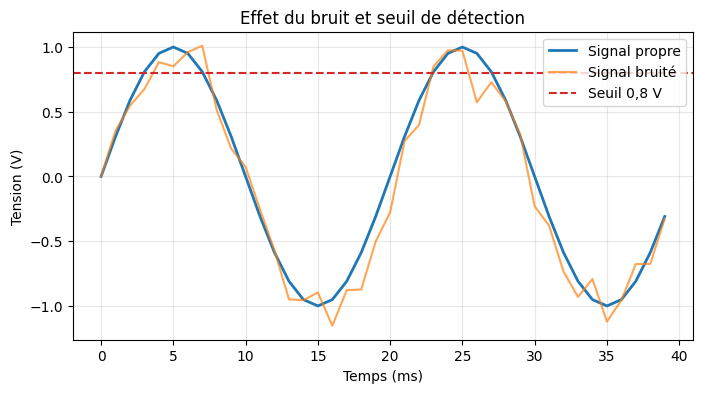

In [4]:
rng = np.random.default_rng(7)  # générateur reproductible pour le bruit
bruit = rng.normal(0.0, 0.15, t.size)  # bruit gaussien d'écart-type 0,15 V
signal_bruite = signal + bruit  # acquisition réelle simulée

fig, ax = plt.subplots(figsize=(8.0, 4.0))  # nouvelle figure
ax.plot(t * 1000.0, signal, label="Signal propre", linewidth=2.0)  # courbe épaisse de référence
ax.plot(t * 1000.0, signal_bruite, label="Signal bruité", color="tab:orange", alpha=0.7)  # courbe semi-transparente
ax.axhline(0.8, color="tab:red", linestyle="--", label="Seuil 0,8 V")  # ligne horizontale pointillée
ax.set_xlabel("Temps (ms)")  # axe horizontal
ax.set_ylabel("Tension (V)")  # axe vertical
ax.set_title("Effet du bruit et seuil de détection")  # titre
ax.legend(loc="upper right")  # affiche la légende avec les libellés
ax.grid(True, alpha=0.3)  # grille discrète
plt.show()  # affiche


**Bon réflexe** : tout graphique qui compare des grandeurs doit avoir une
légende et des unités. On précise aussi `alpha` pour voir les courbes
superposées et `color` pour distinguer les séries.


## 3. Sous-graphiques : signal et histogramme

Une figure peut contenir plusieurs axes. `plt.subplots(2, 1)` crée deux
graphiques empilés. L'histogramme du bruit montre sa distribution : un bruit
gaussien doit ressembler à une cloche centrée sur zéro.


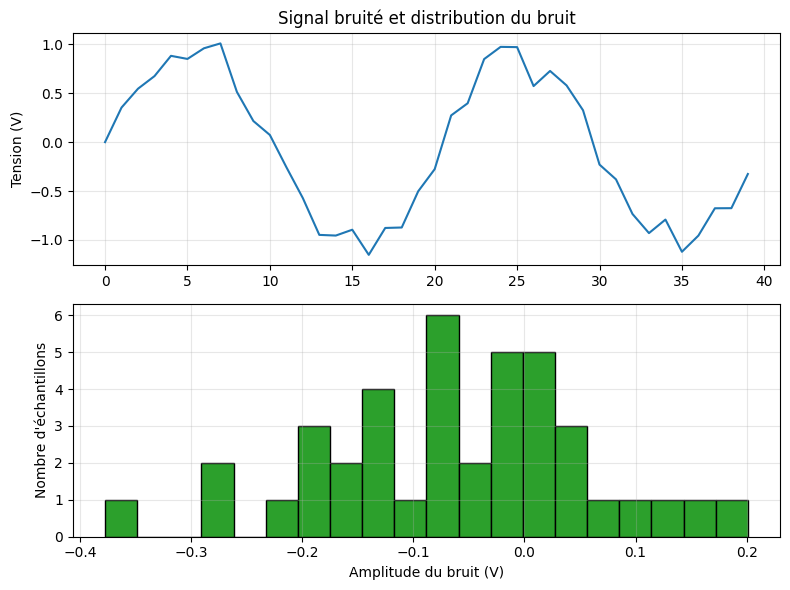

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.0, 6.0))  # deux axes verticaux
ax1.plot(t * 1000.0, signal_bruite, color="tab:blue")  # signal temporel en haut
ax1.set_ylabel("Tension (V)")  # unité de l'axe vertical
ax1.set_title("Signal bruité et distribution du bruit")  # titre commun
ax1.grid(True, alpha=0.3)  # grille en haut

ax2.hist(bruit, bins=20, color="tab:green", edgecolor="black")  # histogramme : 20 intervalles
ax2.set_xlabel("Amplitude du bruit (V)")  # axe horizontal de l'histogramme
ax2.set_ylabel("Nombre d'échantillons")  # effectif par intervalle
ax2.grid(True, alpha=0.3)  # grille en bas

fig.tight_layout()  # ajuste les marges pour éviter les chevauchements
plt.show()  # affiche


## 4. Nuage de points : courbe de calibration

Une CTN (thermistance à coefficient de température négatif) fait chuter sa
résistance quand la température monte. La relation n'est **pas** linéaire :
le nuage de points le montre immédiatement. `np.loadtxt` lit le fichier CSV
généré par `scripts/generer_donnees.py`.


In [6]:
donnees = np.loadtxt("data/calibration_thermistance.csv", delimiter=",", skiprows=1)  # lit les 2 colonnes numériques
temperature = donnees[:, 0]  # première colonne : température en °C
resistance = donnees[:, 1]  # deuxième colonne : résistance en ohms
print(temperature.shape, resistance.shape)  # 150 points pour chaque grandeur


(150,) (150,)


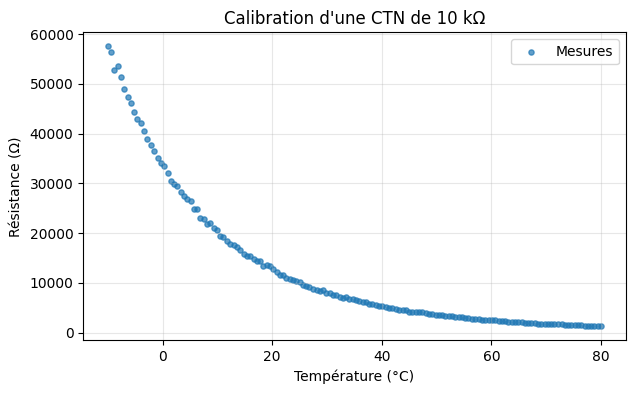

In [7]:
fig, ax = plt.subplots(figsize=(7.0, 4.0))  # figure dédiée à la calibration
ax.scatter(temperature, resistance, s=14, alpha=0.7, label="Mesures")  # nuage de points
ax.set_xlabel("Température (°C)")  # axe horizontal
ax.set_ylabel("Résistance (Ω)")  # axe vertical
ax.set_title("Calibration d'une CTN de 10 kΩ")  # titre
ax.grid(True, alpha=0.3)  # grille
ax.legend()  # légende
plt.show()  # affiche


La courbe est fortement non linéaire. C'est exactement le genre de relation
qu'un modèle de régression devra apprendre au notebook 10 : un modèle linéaire
simple ne suffira pas sur toute la plage.


## 5. Diagramme en barres : inventaire de composants

Un dictionnaire se prête bien à un inventaire. `ax.bar` attend les étiquettes
et les hauteurs ; on ajoute les valeurs au-dessus de chaque barre avec
`ax.bar_label`.


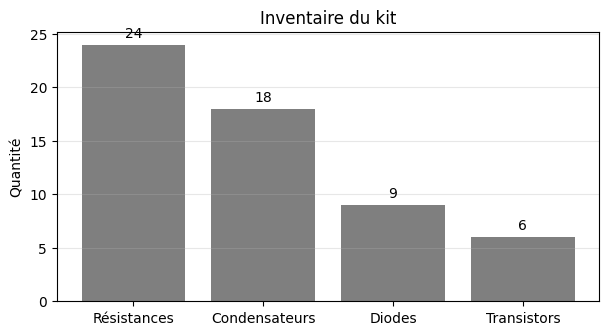

In [8]:
composants = {"Résistances": 24, "Condensateurs": 18, "Diodes": 9, "Transistors": 6}  # inventaire
fig, ax = plt.subplots(figsize=(7.0, 3.5))  # figure
barres = ax.bar(composants.keys(), composants.values(), color="tab:gray")  # une barre par catégorie
ax.set_ylabel("Quantité")  # axe vertical
ax.set_title("Inventaire du kit")  # titre
ax.bar_label(barres, padding=3)  # écrit la valeur au-dessus de chaque barre
ax.grid(True, axis="y", alpha=0.3)  # grille horizontale seulement
plt.show()  # affiche


## 6. Enregistrer une figure

Pour un rapport ou une présentation, on enregistre la figure dans un fichier.
Le dossier `figures/` est prévu pour cela. `dpi` règle la résolution et
`bbox_inches="tight"` évite les marges vides.


Figure enregistrée dans figures/signal_50hz.png


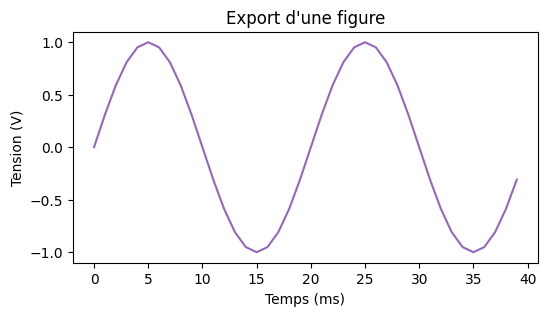

In [9]:
fig, ax = plt.subplots(figsize=(6.0, 3.0))  # petite figure pour l'export
ax.plot(t * 1000.0, signal, color="tab:purple")  # courbe à exporter
ax.set_xlabel("Temps (ms)")  # axe horizontal
ax.set_ylabel("Tension (V)")  # axe vertical
ax.set_title("Export d'une figure")  # titre
fig.savefig("figures/signal_50hz.png", dpi=110, bbox_inches="tight")  # enregistre le fichier PNG
print("Figure enregistrée dans figures/signal_50hz.png")  # confirme l'écriture
plt.show()  # affiche aussi dans le notebook


## 7. À vous de jouer

**Exercice 1** — Tracez la décharge d'un condensateur :
`u(t) = 5 · exp(-t / (R·C))` avec R = 10 kΩ, C = 100 µF, sur 0 à 5 s.
Ajoutez un titre, les unités et une grille.


In [10]:
# TODO : créez t_decharge = np.linspace(0.0, 5.0, 200)

# TODO : créez u_decharge = 5.0 * np.exp(-t_decharge / (10_000.0 * 100e-6))

# TODO : créez fig, ax = plt.subplots(figsize=(8.0, 3.5))

# TODO : tracez u_decharge, ajoutez les libellés, la grille, puis plt.show()


**Exercice 2** — Superposez deux sinusoïdes de 50 Hz, d'amplitudes 1 V et
0,5 V, sur 40 ms. Ajoutez une légende et une ligne verticale au maximum de la
première courbe avec `ax.axvline`.


In [11]:
# TODO : calculez signal_fort et signal_faible

# TODO : tracez les deux courbes avec des couleurs différentes et une légende

# TODO : placez ax.axvline(t[np.argmax(signal_fort)] * 1000.0, ...) puis affichez


## 8. À retenir

- `fig, ax = plt.subplots()` puis `ax.plot`, `ax.scatter`, `ax.hist`, `ax.bar`.
- Toujours : titre, axes avec unités, grille et légende si plusieurs courbes.
- `ax.axhline` / `ax.axvline` marquent un seuil ; `fig.tight_layout()` évite les chevauchements.
- `fig.savefig("figures/...", dpi=110)` exporte la figure.

**Notebook suivant** : `08 — Pandas : analyser des mesures de capteurs`.
